In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
image = cv2.imread('/content/apple.webp')

In [3]:
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

In [4]:
gray_image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

In [5]:
sobel_x = cv2.Sobel(gray_image, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray_image, cv2.CV_64F, 0, 1, ksize=3)

sobel_magnitude = cv2.magnitude(sobel_x, sobel_y)

sobel = cv2.normalize(
    sobel_magnitude, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

In [6]:
box = cv2.blur(gray_image, (3, 3))

In [7]:
weighted_mask = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=np.float32) / 16

weighted_average = cv2.filter2D(
    gray_image, -1, weighted_mask
)

In [8]:
gaussian = cv2.GaussianBlur(
    gray_image, (5, 5), 1.0
)

In [9]:
sharpen_mask = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=np.float32)

sharpening = cv2.filter2D(
    gray_image, -1, sharpen_mask
)

In [10]:
minimum = cv2.erode(
    gray_image, np.ones((3, 3), dtype=np.uint8)
)

In [11]:
maximum = cv2.dilate(
    gray_image, np.ones((3, 3), dtype=np.uint8)
)

In [12]:
mean = cv2.blur(gray_image, (3, 3))

In [13]:
median = cv2.medianBlur(gray_image, 3)

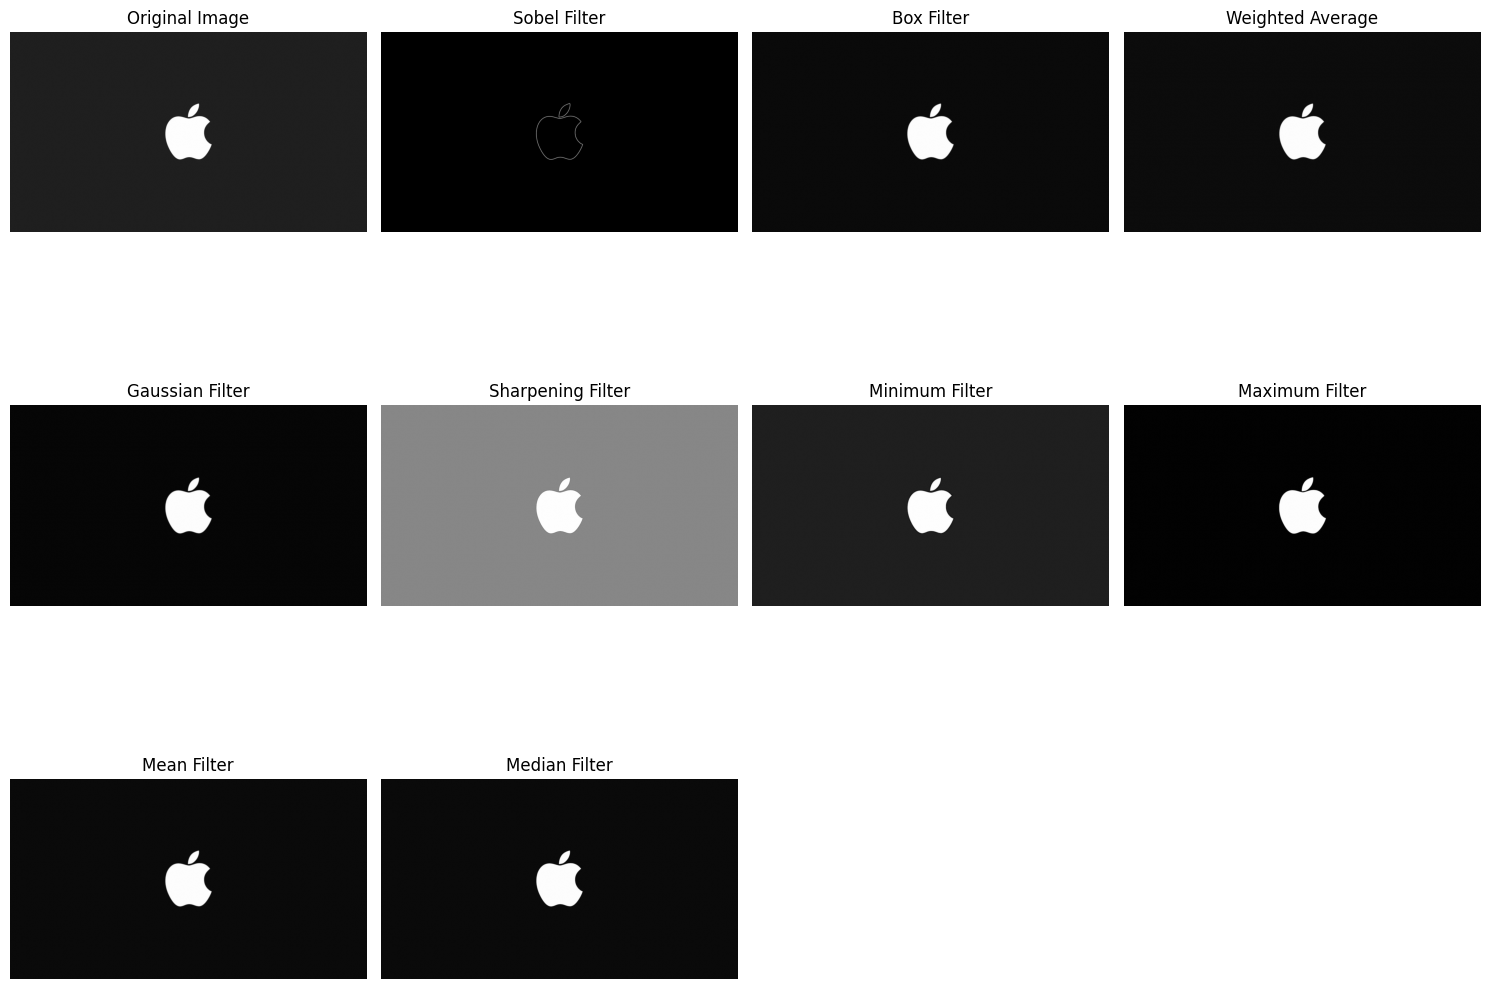

In [14]:
results = [
    ('Original Image', gray_image),
    ('Sobel Filter', sobel),
    ('Box Filter', box),
    ('Weighted Average', weighted_average),
    ('Gaussian Filter', gaussian),
    ('Sharpening Filter', sharpening),
    ('Minimum Filter', minimum),
    ('Maximum Filter', maximum),
    ('Mean Filter', mean),
    ('Median Filter', median)
]

plt.figure(figsize=(15, 12))

for i, (title, result) in enumerate(results):
    plt.subplot(3, 4, i + 1)
    plt.imshow(result, cmap='gray')
    plt.title(title)
    plt.axis('off')

plt.tight_layout()
plt.show()